# Early Warning of Food Price Spikes in Sri Lankan Markets
## Four machine-learning models, model selection, and SHAP explanations

### The problem (why it matters)
Food is a large part of household spending in Sri Lanka, and prices can jump from one month to the next. Sudden rises hurt low-income families most, and the 2022 economic crisis showed how fast food prices can climb. If we can **warn that a food item is likely to become much more expensive next month**, households, traders and the authorities get time to react (stock up, release stocks, import, or target support).

**Question:** *Will the retail price of this food item, in this market, rise by 10% or more next month?*

**Type of task:** classification (spike = yes or no).

### The data (real-world)
Retail food prices collected by the **UN World Food Programme (WFP)** in Sri Lankan markets, published on the Humanitarian Data Exchange. The file has 32,496 price records for 44 markets and 42 items (rice, vegetables, fish, eggs, pulses, fuel and more) from 2004 to September 2025, in Sri Lankan rupees (LKR). Coverage is thin before 2023 and dense from mid-2023 (about 1,000 price records every month).

### The plan
1. Explore the data
2. Build features from **past** prices only
3. Split by **time** into train, validation and test
4. Train four models: **Random Forest, XGBoost, LightGBM, CatBoost**
5. Pick the best on validation, report it on the unseen test period
6. Use **SHAP** to explain what drives spike predictions

In [1]:
import os, re, sys, json, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import joblib, shap
from pathlib import Path
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             precision_score, recall_score, f1_score, confusion_matrix)
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
warnings.filterwarnings('ignore')

ROOT = Path('..') if Path('../data').exists() else Path('.')
sys.path.insert(0, str(ROOT.resolve()))
from backend.explain import positive_class_shap
(ROOT/'models').mkdir(exist_ok=True); (ROOT/'outputs').mkdir(exist_ok=True)
FAST = os.environ.get('FAST') == '1'       # quick smoke-test mode (not used for the real results)
SEED = 42
SPIKE = 0.10                                # a "spike" = price rises by 10% or more

BLUE, ORANGE, AQUA, YELLOW, MUTED, INK = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#898781', '#0b0b0b'
plt.rcParams.update({'figure.facecolor':'#fcfcfb','axes.facecolor':'#fcfcfb','axes.edgecolor':MUTED,'axes.grid':True,
    'grid.color':'#e6e5e1','grid.linewidth':0.8,'axes.spines.top':False,'axes.spines.right':False,'axes.labelcolor':'#52514e',
    'xtick.color':'#52514e','ytick.color':'#52514e','text.color':INK,'axes.titleweight':'bold','axes.titlesize':12,
    'figure.dpi':110,'lines.linewidth':1.8})

/usr/local/lib/python3.11/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load and explore the data

In [2]:
raw = pd.read_csv(ROOT/'data'/'wfp_food_prices_lka.csv', parse_dates=['date'])
print(raw.shape)
raw.head()

(32496, 16)


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2004-01-15,Western,Colombo,Colombo City,368,6.93,79.85,cereals and tubers,Rice (red nadu),157,KG,actual,Retail,LKR,32.71,0.33
1,2004-01-15,Western,Colombo,Colombo City,368,6.93,79.85,cereals and tubers,Wheat flour,58,KG,actual,Retail,LKR,26.66,0.27
2,2004-02-15,Western,Colombo,Colombo City,368,6.93,79.85,cereals and tubers,Rice (red nadu),157,KG,actual,Retail,LKR,33.62,0.34
3,2004-02-15,Western,Colombo,Colombo City,368,6.93,79.85,cereals and tubers,Wheat flour,58,KG,actual,Retail,LKR,26.71,0.27
4,2004-03-15,Western,Colombo,Colombo City,368,6.93,79.85,cereals and tubers,Rice (red nadu),157,KG,actual,Retail,LKR,32.92,0.34


In [3]:
print('Date range:', raw.date.min().date(), 'to', raw.date.max().date())
print('Markets:', raw.market.nunique(), '| Items:', raw.commodity.nunique(), '| Price types:', raw.pricetype.value_counts().to_dict())
print('Rows with no location (the "National Average" rows):', int(raw.admin1.isna().sum()))
print('Missing price values:', int(raw.price.isna().sum()))
raw.groupby('category').size().sort_values(ascending=False)

Date range: 2004-01-15 to 2025-09-15
Markets: 44 | Items: 42 | Price types: {'Retail': 31898, 'Wholesale': 598}
Rows with no location (the "National Average" rows): 194
Missing price values: 0


category
vegetables and fruits    12037
meat, fish and eggs       8705
cereals and tubers        6188
pulses and nuts           3639
miscellaneous food        1429
non-food                   478
oil and fats                20
dtype: int64

**What we learn:** the file has one price per market, item and month. It also contains "National Average" rows (no location), wholesale prices, and fuel. For a *household food price* question we keep **retail food prices in real markets** and drop the rest.

The chart below shows how many price records exist per month. Before mid-2023 the data is thin; from mid-2023 it is dense.

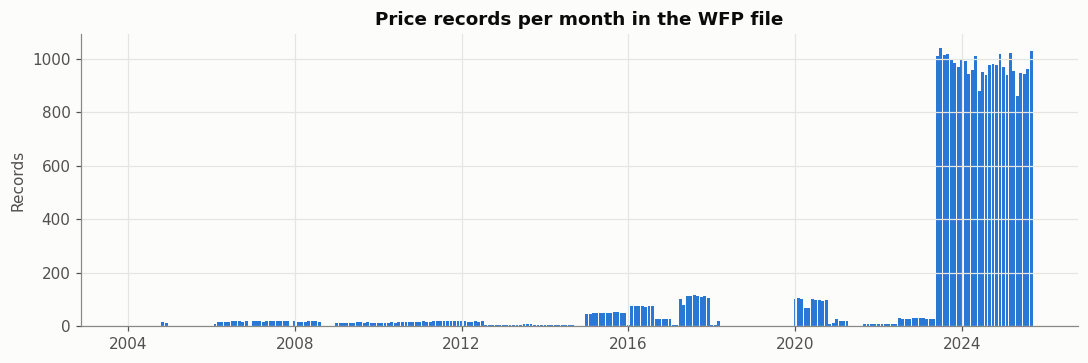

In [4]:
cnt = raw.groupby(raw.date.dt.to_period('M')).size()
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(cnt.index.to_timestamp(), cnt.values, width=25, color=BLUE)
ax.set_title('Price records per month in the WFP file'); ax.set_ylabel('Records'); fig.tight_layout()
fig.savefig(ROOT/'outputs'/'eda_records_per_month.png'); plt.show()

## 2. Clean the data and build features

**Cleaning:** keep retail prices of food items in real markets (drop "National Average", wholesale, fuel), drop items with fewer than 100 records, and keep one record per market, item and month.

**Features (all use only information up to the *last* month, never the month we predict):**

| Feature | Meaning |
|---|---|
| `price_now` | Latest known price (LKR) of the item in the market |
| `change_1m` | How much the price changed in the last month (log change) |
| `change_2m` | The change the month before that |
| `vs_3m_avg` | Is the latest price above or below its 3-month average? |
| `national_avg_now` | Latest national average price for that item |
| `national_change_1m` | Change in that national average over the last month |
| `market_vs_national` | Is this market more or less expensive than the national average? |
| `month` | Calendar month we are predicting (captures seasons) |
| `latitude`, `longitude`, `province_*` | Where the market is |
| `commodity_*` | Which item it is (one 0/1 column per item) |

**Target:** `spike` = 1 if next month's price is at least 10% higher than the latest price, otherwise 0.

In [5]:
d = raw[(raw.market != 'National Average') & (raw.pricetype == 'Retail') & (raw.category != 'non-food')].copy()
d['ym'] = d.date.dt.to_period('M')
keep = d.groupby('commodity').size(); d = d[d.commodity.isin(keep[keep >= 100].index)]
d = d.sort_values(['market', 'commodity', 'ym']).drop_duplicates(['market', 'commodity', 'ym']).reset_index(drop=True)
print('Rows after cleaning:', len(d), '| items:', d.commodity.nunique(), '| markets:', d.market.nunique())

def lagged(frame, col, k, name):          # value of `col` from k months earlier, matched on exact month
    t = frame[['market', 'commodity', 'ym', col]].copy(); t['ym'] = t['ym'] + k
    return t.rename(columns={col: name})
for k, name in ((1, 'price_now'), (2, 'price_prev'), (3, 'price_3m')):
    d = d.merge(lagged(d, 'price', k, name), on=['market', 'commodity', 'ym'], how='left')

nat = d.groupby(['commodity', 'ym']).price.mean().rename('nat').reset_index()
for k, name in ((1, 'nat_now'), (2, 'nat_prev')):
    t = nat.copy(); t['ym'] = t['ym'] + k
    d = d.merge(t.rename(columns={'nat': name}), on=['commodity', 'ym'], how='left')

d = d.dropna(subset=['price_now', 'price_prev', 'price_3m', 'nat_now', 'nat_prev']).drop(columns=['commodity_id', 'market_id']).copy()
d['change_1m'] = np.log(d.price_now / d.price_prev)
d['change_2m'] = np.log(d.price_prev / d.price_3m)
d['vs_3m_avg'] = np.log(d.price_now / ((d.price_now + d.price_prev + d.price_3m) / 3))
d['national_avg_now'] = d.nat_now
d['national_change_1m'] = np.log(d.nat_now / d.nat_prev)
d['market_vs_national'] = np.log(d.price_now / d.nat_now)
d['month'] = d.date.dt.month
d['spike'] = (d.price >= (1 + SPIKE) * d.price_now).astype(int)
print('Rows with a full 3-month price history:', len(d), '| spike rate:', round(d.spike.mean(), 3))

Rows after cleaning: 31246 | items: 37 | markets: 42
Rows with a full 3-month price history: 22575 | spike rate: 0.19


About **1 in 6 item-market-months is a spike**, so the classes are imbalanced. That is why we use ROC-AUC and PR-AUC (which work well with imbalance) and not plain accuracy: a model that always says "no spike" would be about 83% accurate and completely useless.

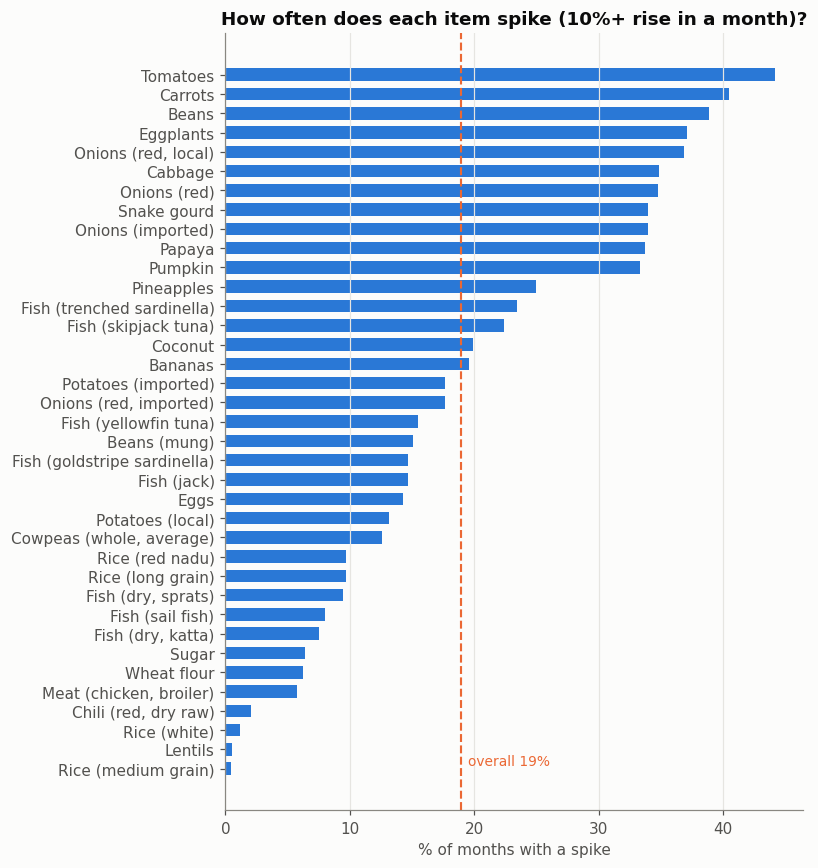

In [6]:
rate = d.groupby('commodity').spike.agg(['mean', 'size']).query('size >= 200').sort_values('mean')
fig, ax = plt.subplots(figsize=(7.5, 8))
ax.barh(rate.index, rate['mean'] * 100, color=BLUE, height=0.65); ax.grid(axis='y', visible=False)
ax.axvline(d.spike.mean() * 100, color=ORANGE, linestyle='--', linewidth=1.4)
ax.text(d.spike.mean() * 100 + 0.5, 0.2, f'overall {d.spike.mean()*100:.0f}%', color=ORANGE, fontsize=9)
ax.set_title('How often does each item spike (10%+ rise in a month)?'); ax.set_xlabel('% of months with a spike')
fig.tight_layout(); fig.savefig(ROOT/'outputs'/'eda_spike_rate_by_item.png'); plt.show()

**What the chart shows:** vegetables such as tomatoes, carrots and eggplant spike very often, while staples such as rice, sugar and wheat flour almost never do. So "which item is it" is a strong clue, and a good model should do better than that alone. The baseline below tests exactly this.

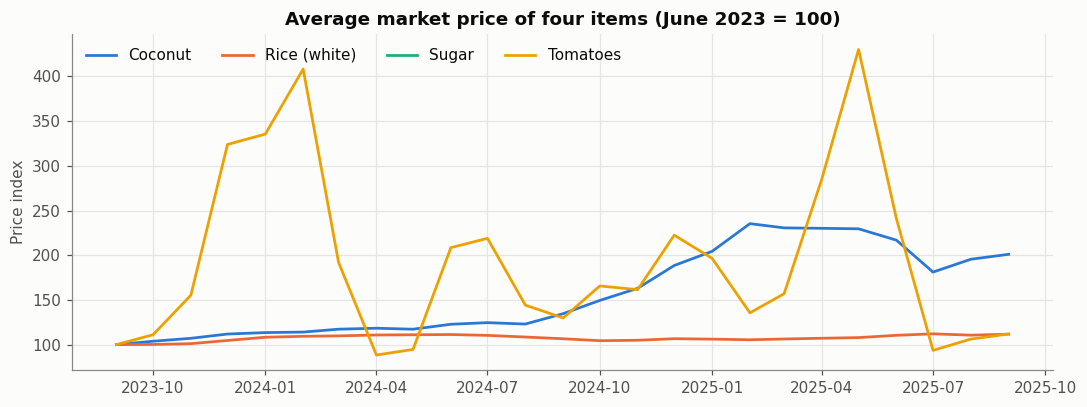

In [7]:
eg = d[d.commodity.isin(['Tomatoes', 'Rice (white)', 'Coconut', 'Sugar'])]
idx = eg.groupby(['commodity', 'ym']).price.mean().unstack(0)
idx = idx[idx.index >= pd.Period('2023-06')]; idx = idx / idx.iloc[0] * 100
fig, ax = plt.subplots(figsize=(10, 3.8))
for c, col in zip(idx.columns, [BLUE, ORANGE, AQUA, YELLOW]): ax.plot(idx.index.to_timestamp(), idx[c], label=c, color=col)
ax.set_title('Average market price of four items (June 2023 = 100)'); ax.set_ylabel('Price index'); ax.legend(frameon=False, ncol=4)
fig.tight_layout(); fig.savefig(ROOT/'outputs'/'eda_price_index.png'); plt.show()

## 3. Final feature table and time split
* **Train:** target month up to June 2024. Models learn and are tuned here.
* **Validation:** July to December 2024. Used to **choose the best model** and the alert threshold.
* **Test:** January to September 2025. Used once, for the final honest score.

We split by time, never at random, because a real early-warning system only ever sees the past.

One row is **held out** for the inference demo: the price of Tomatoes in Colombo City in **September 2025**, predicted from prices up to August 2025. It is removed from train, validation and test.

In [8]:
# LightGBM does not accept special characters (brackets, commas) in column names, so we make clean names and remember the originals
clean = lambda x: re.sub(r'[^0-9A-Za-z]+', '_', x).strip('_')
PRETTY = {clean(c): c for c in d.commodity.unique()}              # clean name -> original name, e.g. Chili_red_dry_raw -> Chili (red, dry raw)
d['commodity'] = d.commodity.map(clean); d['admin1'] = d.admin1.map(clean)
d = pd.get_dummies(d, columns=['commodity', 'admin1'], prefix=['commodity', 'province'], dtype=int)
PROV = [c for c in d.columns if c.startswith('province_')]
COMM = [c for c in d.columns if c.startswith('commodity_')]
NUM = ['price_now', 'change_1m', 'change_2m', 'vs_3m_avg', 'national_avg_now', 'national_change_1m', 'market_vs_national', 'month', 'latitude', 'longitude']
FEATURES = NUM + PROV + COMM
print(len(FEATURES), 'features:', len(NUM), 'numeric,', len(PROV), 'province columns,', len(COMM), 'item columns')

hold_mask = (d.market == 'Colombo City') & (d['commodity_Tomatoes'] == 1) & (d.ym == d.ym.max())
assert hold_mask.sum() == 1, 'held-out row not found'
hold = d[hold_mask].iloc[0]
data = d[~hold_mask].sort_values('ym').reset_index(drop=True)

train_m = data.ym <= pd.Period('2024-06'); val_m = (data.ym >= pd.Period('2024-07')) & (data.ym <= pd.Period('2024-12')); test_m = data.ym >= pd.Period('2025-01')
if FAST: train_m = train_m & (np.arange(len(data)) % 6 == 0)
X_train, y_train = data.loc[train_m, FEATURES], data.loc[train_m, 'spike']
X_val, y_val = data.loc[val_m, FEATURES], data.loc[val_m, 'spike']
X_test, y_test = data.loc[test_m, FEATURES], data.loc[test_m, 'spike']
print(f'Train {len(X_train):,} (spike rate {y_train.mean():.3f}) | Validation {len(X_val):,} ({y_val.mean():.3f}) | Test {len(X_test):,} ({y_test.mean():.3f})')

56 features: 10 numeric, 9 province columns, 37 item columns
Train 11,163 (spike rate 0.194) | Validation 4,527 (0.208) | Test 6,884 (0.171)


## 4. Evaluation metrics and a baseline
* **ROC-AUC:** chance that the model ranks a real spike above a non-spike (0.5 = guessing, 1.0 = perfect). **Used to choose the best model.**
* **PR-AUC (average precision):** how well spikes are found while keeping false alarms low. Compare it with the spike rate (guessing gives about that value).
* **Precision, recall, F1** at an alert threshold chosen on validation: precision = of the alerts, how many were real; recall = of the real spikes, how many we caught.

**Baseline:** "each item's usual spike rate in the training period". This captures "tomatoes are volatile, rice is not". The models must beat it to be worth using.

In [9]:
results, probs, fitted = [], {}, {}
def best_threshold(y, p):
    pr, rc, th = precision_recall_curve(y, p); f1 = 2 * pr[:-1] * rc[:-1] / np.clip(pr[:-1] + rc[:-1], 1e-9, None)
    return float(th[np.argmax(f1)])

def record(name, p_val, p_test, seconds=0.0, model=None):
    thr = best_threshold(y_val, p_val); pred = (p_test >= thr).astype(int)
    results.append(dict(Model=name, Val_AUC=roc_auc_score(y_val, p_val), Val_PR_AUC=average_precision_score(y_val, p_val),
        Test_AUC=roc_auc_score(y_test, p_test), Test_PR_AUC=average_precision_score(y_test, p_test), Threshold=thr,
        Test_Precision=precision_score(y_test, pred, zero_division=0), Test_Recall=recall_score(y_test, pred), Test_F1=f1_score(y_test, pred),
        Train_seconds=seconds))
    probs[name] = (np.asarray(p_val), np.asarray(p_test))
    if model is not None: fitted[name] = model
    r = results[-1]; print(f"{name:<28} val AUC {r['Val_AUC']:.3f} | test AUC {r['Test_AUC']:.3f} | test PR-AUC {r['Test_PR_AUC']:.3f} | F1 {r['Test_F1']:.3f} | {seconds:5.1f}s")

# baseline: each item's spike rate in the training period
item_rate = {c: (data.loc[train_m & (data[c] == 1), 'spike'].mean() if (train_m & (data[c] == 1)).any() else y_train.mean()) for c in COMM}
def baseline_scores(X): return np.asarray([item_rate[[c for c in COMM if r[c] == 1][0]] for _, r in X[COMM].iterrows()])
record('Baseline: item spike rate', baseline_scores(X_val), baseline_scores(X_test))

Baseline: item spike rate    val AUC 0.711 | test AUC 0.664 | test PR-AUC 0.248 | F1 0.363 |   0.0s


## 5. The four models
All four are **tree ensembles**, but they combine trees differently:
* **Random Forest** builds many trees independently and **averages** their votes.
* **XGBoost** builds trees **one after another**; each new tree corrects the errors of the previous ones.
* **LightGBM** is a faster boosting library that grows trees leaf by leaf.
* **CatBoost** is a boosting library with built-in protection against over-fitting.

Each model is tuned with `RandomizedSearchCV` using `TimeSeriesSplit` (each fold validates on a period *after* its training data), scored by ROC-AUC, **on the training period only**.

In [10]:
tscv = TimeSeriesSplit(n_splits=3)
def tune(name, estimator, space, n_iter):
    s = RandomizedSearchCV(estimator, space, n_iter=(2 if FAST else n_iter), cv=tscv, scoring='roc_auc', random_state=SEED, n_jobs=1)
    t0 = time.time(); s.fit(X_train, y_train); sec = time.time() - t0
    m = s.best_estimator_; print('   best settings:', s.best_params_, '| CV AUC', round(s.best_score_, 3))
    record(name, m.predict_proba(X_val)[:, 1], m.predict_proba(X_test)[:, 1], sec, m); return m

rf = tune('Random Forest', RandomForestClassifier(random_state=SEED, n_jobs=2),
          {'n_estimators': [200, 300], 'max_depth': [6, 10, 14, None], 'min_samples_leaf': [5, 10, 20], 'max_features': ['sqrt', 0.3, 0.5]}, 8)
xgb = tune('XGBoost', XGBClassifier(random_state=SEED, n_jobs=2, eval_metric='logloss'),
           {'n_estimators': [200, 400, 600], 'max_depth': [3, 4, 6], 'learning_rate': [0.02, 0.03, 0.05, 0.1],
            'subsample': [0.7, 0.85, 1.0], 'colsample_bytree': [0.6, 0.8, 1.0], 'min_child_weight': [1, 5, 10]}, 12)
lgbm = tune('LightGBM', LGBMClassifier(random_state=SEED, n_jobs=2, verbose=-1),
            {'n_estimators': [200, 400, 600], 'num_leaves': [8, 15, 31], 'learning_rate': [0.02, 0.03, 0.05, 0.1],
             'subsample': [0.7, 0.85, 1.0], 'subsample_freq': [1], 'colsample_bytree': [0.6, 0.8, 1.0], 'min_child_samples': [10, 30, 60]}, 12)
cat = tune('CatBoost', CatBoostClassifier(verbose=0, thread_count=2, random_seed=SEED),
           {'iterations': [300, 500], 'depth': [4, 6, 8], 'learning_rate': [0.03, 0.05, 0.1], 'l2_leaf_reg': [1, 3, 10]}, 5)

   best settings: {'n_estimators': 200, 'min_samples_leaf': 10, 'max_features': 0.3, 'max_depth': None} | CV AUC 0.78


Random Forest                val AUC 0.778 | test AUC 0.672 | test PR-AUC 0.263 | F1 0.360 |  27.0s


   best settings: {'subsample': 0.85, 'n_estimators': 600, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.02, 'colsample_bytree': 0.6} | CV AUC 0.772
XGBoost                      val AUC 0.794 | test AUC 0.691 | test PR-AUC 0.287 | F1 0.360 |  14.4s


   best settings: {'subsample_freq': 1, 'subsample': 0.7, 'num_leaves': 15, 'n_estimators': 200, 'min_child_samples': 60, 'learning_rate': 0.05, 'colsample_bytree': 1.0} | CV AUC 0.773
LightGBM                     val AUC 0.800 | test AUC 0.692 | test PR-AUC 0.282 | F1 0.378 |  12.5s


   best settings: {'learning_rate': 0.1, 'l2_leaf_reg': 10, 'iterations': 300, 'depth': 8} | CV AUC 0.787
CatBoost                     val AUC 0.776 | test AUC 0.676 | test PR-AUC 0.282 | F1 0.353 |  18.2s


## 6. Compare the models and select the best
The best model is chosen on **validation ROC-AUC**. Test results are shown for the final report and were not used for any choice.

In [11]:
res = pd.DataFrame(results).set_index('Model').sort_values('Val_AUC', ascending=False)
res.round(3).to_csv(ROOT/'outputs'/'metrics.csv')
four = ['Random Forest', 'XGBoost', 'LightGBM', 'CatBoost']
best_name = res.loc[four, 'Val_AUC'].idxmax()
print('Selected model (highest validation ROC-AUC among the four):', best_name)
res[['Val_AUC', 'Test_AUC', 'Test_PR_AUC', 'Test_Precision', 'Test_Recall', 'Test_F1', 'Train_seconds']].round(3)

Selected model (highest validation ROC-AUC among the four): LightGBM


,Val_AUC,Test_AUC,Test_PR_AUC,Test_Precision,Test_Recall,Test_F1,Train_seconds
Model,,,,,,,
LightGBM,0.800,0.692,0.282,0.274,0.608,0.378,12.492
XGBoost,0.794,0.691,0.287,0.265,0.564,0.360,14.405
Random Forest,0.778,0.672,0.263,0.253,0.622,0.360,27.040
CatBoost,0.776,0.676,0.282,0.254,0.578,0.353,18.197
Baseline: item spike rate,0.711,0.664,0.248,0.280,0.518,0.363,0.000


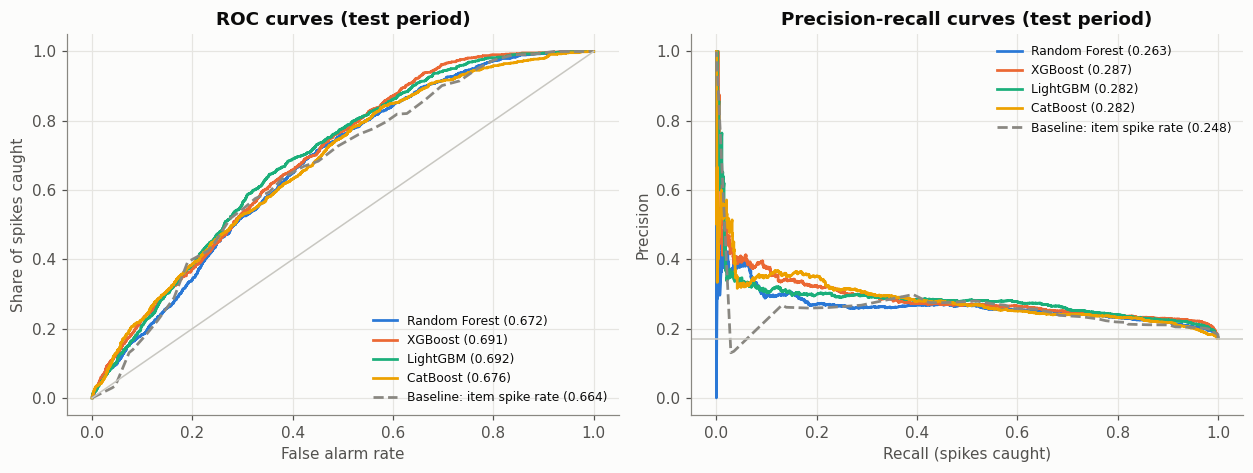

In [12]:
cols = {'Random Forest': BLUE, 'XGBoost': ORANGE, 'LightGBM': AQUA, 'CatBoost': YELLOW, 'Baseline: item spike rate': MUTED}
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
for n, c in cols.items():
    p = probs[n][1]; fpr, tpr, _ = roc_curve(y_test, p); pr, rc, _ = precision_recall_curve(y_test, p)
    ls = '--' if n.startswith('Baseline') else '-'
    axes[0].plot(fpr, tpr, color=c, linestyle=ls, label=f"{n} ({roc_auc_score(y_test, p):.3f})")
    axes[1].plot(rc, pr, color=c, linestyle=ls, label=f"{n} ({average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], color='#c8c7c1', linewidth=1); axes[0].set_title('ROC curves (test period)'); axes[0].set_xlabel('False alarm rate'); axes[0].set_ylabel('Share of spikes caught'); axes[0].legend(frameon=False, fontsize=8, loc='lower right')
axes[1].axhline(y_test.mean(), color='#c8c7c1', linewidth=1); axes[1].set_title('Precision-recall curves (test period)'); axes[1].set_xlabel('Recall (spikes caught)'); axes[1].set_ylabel('Precision'); axes[1].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(ROOT/'outputs'/'roc_pr_curves.png'); plt.show()

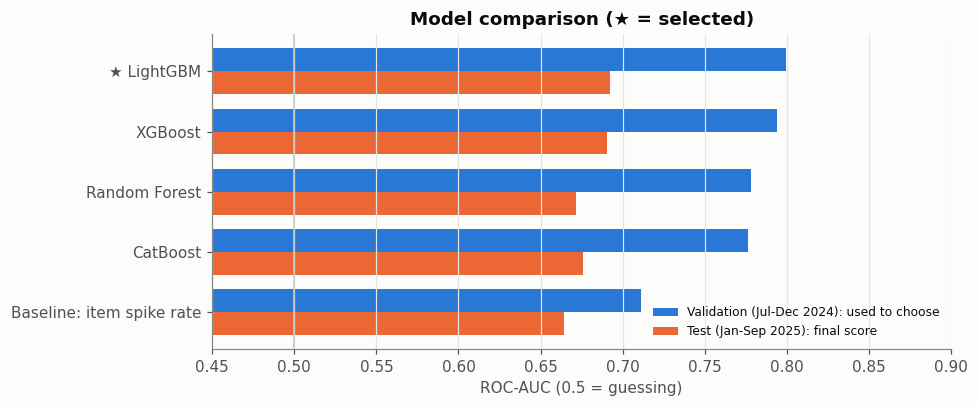

In [13]:
order = res.index[::-1]; yy = np.arange(len(order)); h = 0.38
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(yy + h/2, res.loc[order, 'Val_AUC'], height=h, color=BLUE, label='Validation (Jul-Dec 2024): used to choose')
ax.barh(yy - h/2, res.loc[order, 'Test_AUC'], height=h, color=ORANGE, label='Test (Jan-Sep 2025): final score')
ax.set_yticks(yy); ax.set_yticklabels([('★ ' if n == best_name else '') + n for n in order]); ax.grid(axis='y', visible=False)
ax.set_xlim(0.45, 0.9); ax.axvline(0.5, color='#c8c7c1', linewidth=1); ax.set_xlabel('ROC-AUC (0.5 = guessing)')
ax.set_title('Model comparison (★ = selected)'); ax.legend(frameon=False, loc='lower right', fontsize=8)
fig.tight_layout(); fig.savefig(ROOT/'outputs'/'model_comparison.png'); plt.show()

### Are the top models really different?
Differences between the best models can be small. A **bootstrap** resamples the test set many times to see whether the gap in ROC-AUC could just be luck. We resample whole **months** (not single rows) because rows from the same month are not independent.

In [14]:
def boot_auc_diff(pa, pb, n=1000, seed=0):
    months = data.loc[test_m, 'ym'].astype(str).values; ys = y_test.values; um = np.unique(months)
    groups = {m: np.where(months == m)[0] for m in um}; rng = np.random.default_rng(seed); diffs = []
    for _ in range(n):
        idx = np.concatenate([groups[m] for m in rng.choice(um, len(um))])
        if ys[idx].min() == ys[idx].max(): continue
        diffs.append(roc_auc_score(ys[idx], pa[idx]) - roc_auc_score(ys[idx], pb[idx]))
    return float(np.mean(diffs)), np.percentile(diffs, [2.5, 97.5])
rows = []
for a, b in [(best_name, 'Baseline: item spike rate')] + [(best_name, o) for o in four if o != best_name]:
    m, (lo, hi) = boot_auc_diff(probs[a][1], probs[b][1])
    rows.append({'A': a, 'B': b, 'AUC(A) - AUC(B)': round(m, 3), '95% range low': round(lo, 3), '95% range high': round(hi, 3), 'Clear difference?': 'yes' if (lo > 0 or hi < 0) else 'no'})
pd.DataFrame(rows)

,A,B,AUC(A) - AUC(B),95% range low,95% range high,Clear difference?
0,LightGBM,Baseline: item spike rate,0.031,-0.038,0.109,no
1,LightGBM,Random Forest,0.021,-0.008,0.045,no
2,LightGBM,XGBoost,0.002,-0.012,0.016,no
3,LightGBM,CatBoost,0.016,-0.008,0.043,no


"Clear difference? no" means the gap could easily be chance, so we should not claim one model is truly better than that other model. "yes" means the whole 95% range is on one side of zero.

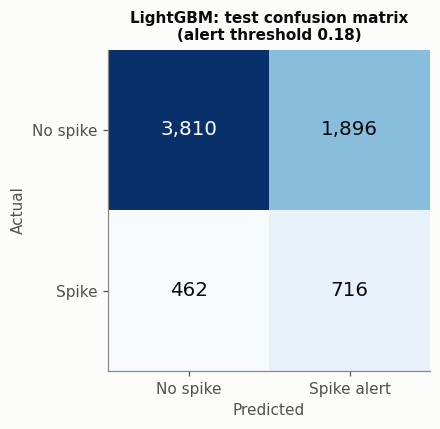

Of the 2,612 alerts, 716 were real spikes (precision 0.27); we caught 716 of 1,178 real spikes (recall 0.61).


In [15]:
best = fitted[best_name]; thr = float(res.loc[best_name, 'Threshold'])
pred = (probs[best_name][1] >= thr).astype(int); cm = confusion_matrix(y_test, pred)
fig, ax = plt.subplots(figsize=(4.6, 4))
ax.imshow(cm, cmap='Blues'); ax.grid(False)
for i in range(2):
    for j in range(2): ax.text(j, i, f'{cm[i, j]:,}', ha='center', va='center', fontsize=13, color='white' if cm[i, j] > cm.max() / 2 else INK)
ax.set_xticks([0, 1]); ax.set_xticklabels(['No spike', 'Spike alert']); ax.set_yticks([0, 1]); ax.set_yticklabels(['No spike', 'Spike'])
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title(f'{best_name}: test confusion matrix\n(alert threshold {thr:.2f})', fontsize=10)
fig.tight_layout(); fig.savefig(ROOT/'outputs'/'confusion_matrix.png'); plt.show()
print(f"Of the {cm[:,1].sum():,} alerts, {cm[1,1]:,} were real spikes (precision {cm[1,1]/cm[:,1].sum():.2f}); we caught {cm[1,1]:,} of {cm[1].sum():,} real spikes (recall {cm[1,1]/cm[1].sum():.2f}).")

## 7. SHAP: why does the model predict a spike?

**SHAP** explains a model's predictions. For every single prediction it says how much each feature **pushed the spike risk up or down**, compared with the average prediction.
* Red/right = pushes the risk **up**; blue/left = pushes it **down**.
* For XGBoost, LightGBM and CatBoost the SHAP unit is *log-odds* (bigger positive = higher spike risk). For Random Forest it is probability.

We explain the **selected model** on a sample of **test** rows. Because item and province are stored as many 0/1 columns, we also **add them back together** to see the total effect of "which item" and "which province".

In [16]:
rng = np.random.default_rng(SEED)
samp = X_test.iloc[np.sort(rng.choice(len(X_test), min(2500 if not FAST else 300, len(X_test)), replace=False))]
sv, base = positive_class_shap(best, samp)
sv_df = pd.DataFrame(sv, columns=FEATURES, index=samp.index)
print('SHAP computed for', len(samp), 'test rows | model:', best_name, '| base value:', round(base, 3))

SHAP computed for 2500 test rows | model: LightGBM | base value: -2.141


### 7.1 Which features matter most overall?
Mean absolute SHAP value per feature (the average size of its push, in either direction).

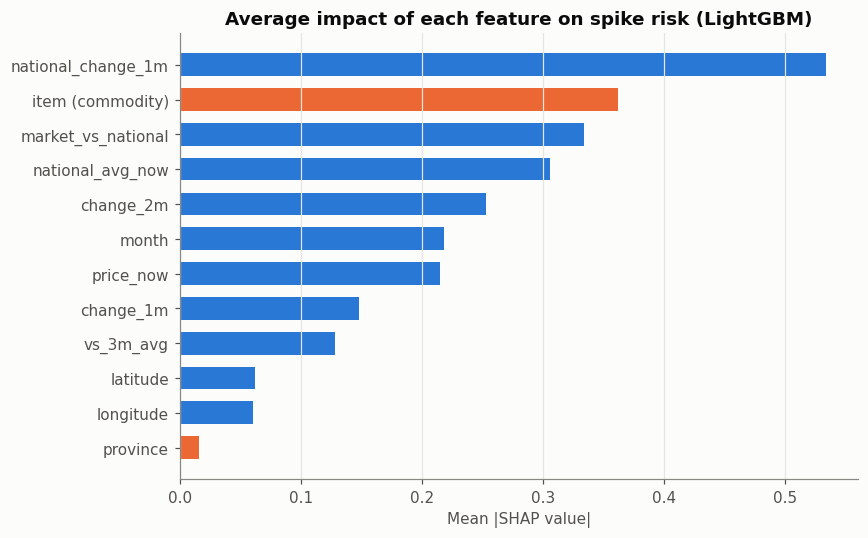

national_change_1m    20.2
item (commodity)      13.7
market_vs_national    12.7
national_avg_now      11.6
change_2m              9.6
month                  8.3


In [17]:
grouped = pd.DataFrame({**{f: sv_df[f] for f in NUM}, 'item (commodity)': sv_df[COMM].sum(axis=1), 'province': sv_df[PROV].sum(axis=1)})
imp = grouped.abs().mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index, imp.values, color=[ORANGE if i in ('item (commodity)', 'province') else BLUE for i in imp.index], height=0.65); ax.grid(axis='y', visible=False)
ax.set_title(f'Average impact of each feature on spike risk ({best_name})'); ax.set_xlabel('Mean |SHAP value|')
fig.tight_layout(); fig.savefig(ROOT/'outputs'/'shap_importance.png'); plt.show()
print((imp[::-1] / imp.sum() * 100).round(1).head(6).to_string())

### 7.2 How does each feature push the prediction? (beeswarm)
Each dot is one test row. Position left/right = push down/up. Colour = the feature's value (red high, blue low).

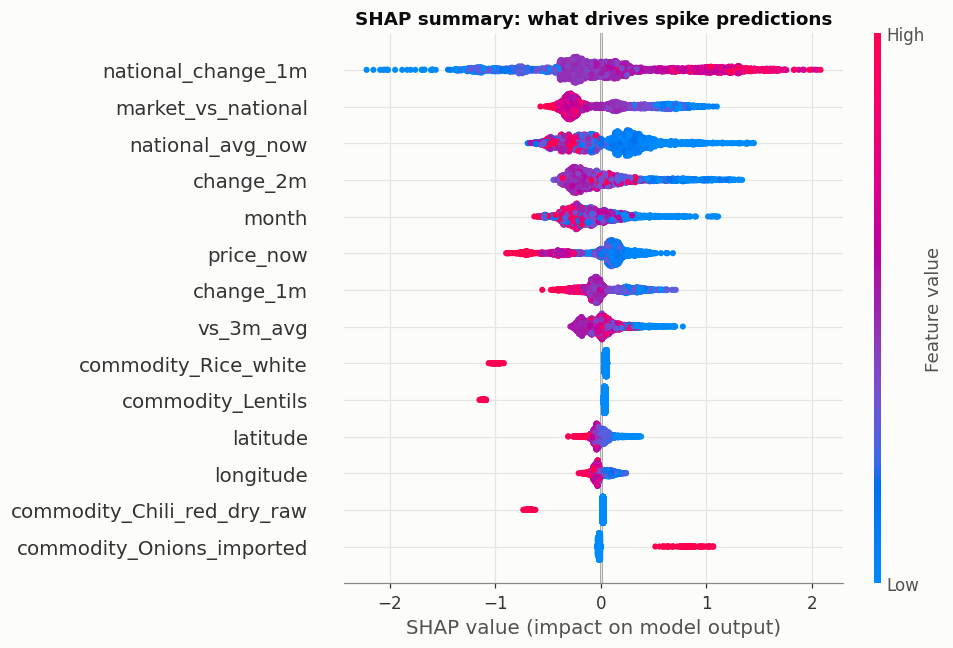

In [18]:
plt.figure(); shap.summary_plot(sv, samp, feature_names=FEATURES, max_display=14, show=False, plot_size=(9, 6))
plt.title('SHAP summary: what drives spike predictions'); plt.tight_layout(); plt.savefig(ROOT/'outputs'/'shap_beeswarm.png', dpi=130, bbox_inches='tight'); plt.show()

### 7.3 Which items carry the highest spike risk?
The average SHAP push of each item's 0/1 column, over the rows where that item appears.

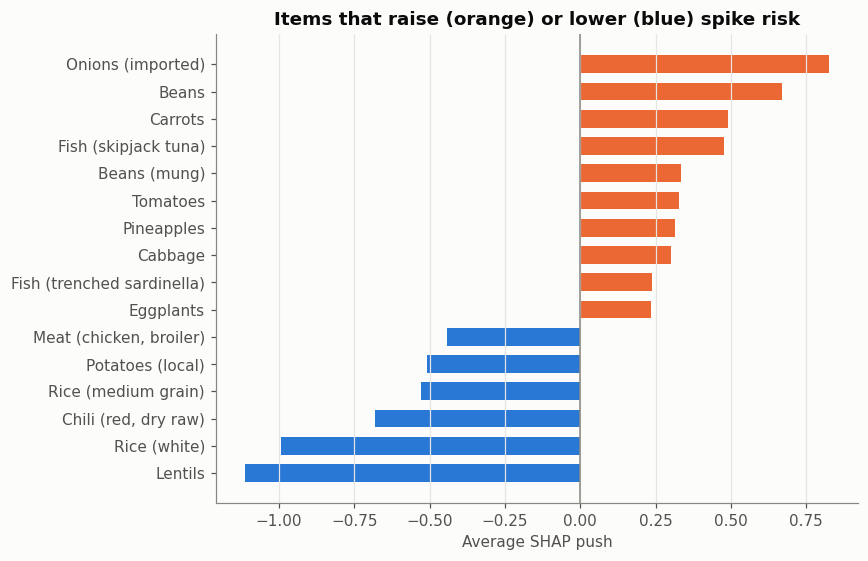

In [19]:
eff = {PRETTY[c.replace('commodity_', '')]: sv_df.loc[samp[c] == 1, c].mean() for c in COMM if (samp[c] == 1).sum() >= 20}
eff = pd.Series(eff).sort_values()
show = pd.concat([eff.head(6), eff.tail(10)])
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh(show.index, show.values, color=[ORANGE if v > 0 else BLUE for v in show.values], height=0.65); ax.grid(axis='y', visible=False); ax.axvline(0, color=MUTED, linewidth=1)
ax.set_title('Items that raise (orange) or lower (blue) spike risk'); ax.set_xlabel('Average SHAP push')
fig.tight_layout(); fig.savefig(ROOT/'outputs'/'shap_items.png'); plt.show()

### 7.4 Dependence plots: the shape of the effect
How the spike risk changes as a single feature changes.

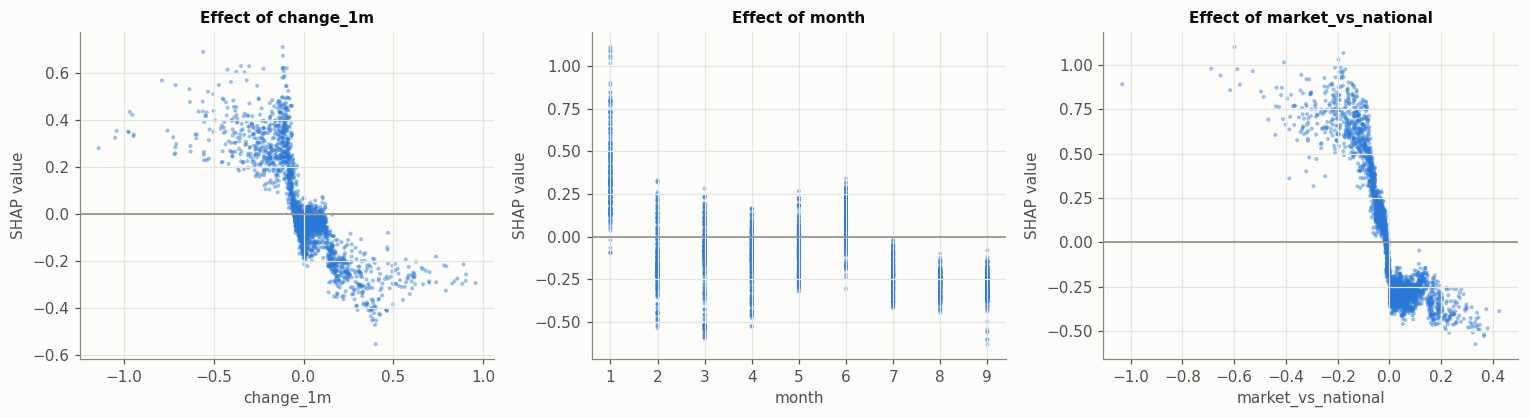

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
for ax, f in zip(axes, ['change_1m', 'month', 'market_vs_national']):
    ax.scatter(samp[f], sv_df[f], s=7, alpha=0.45, color=BLUE, edgecolors='none'); ax.axhline(0, color=MUTED, linewidth=1)
    ax.set_xlabel(f); ax.set_ylabel('SHAP value'); ax.set_title(f'Effect of {f}', fontsize=10)
fig.tight_layout(); fig.savefig(ROOT/'outputs'/'shap_dependence.png'); plt.show()

**How to read these:** a SHAP value above 0 raises the spike risk, below 0 lowers it. If `change_1m` has strongly negative values on the left (price just fell) pushing risk **up**, that is **mean reversion**: items that dropped sharply often bounce back. The `month` plot shows seasonal months with higher risk.

### 7.5 Explaining a single prediction (waterfall)
The held-out example: **Tomatoes, Colombo City**, predicting September 2025 from prices up to August 2025. The waterfall starts at the average risk and adds each feature's push.

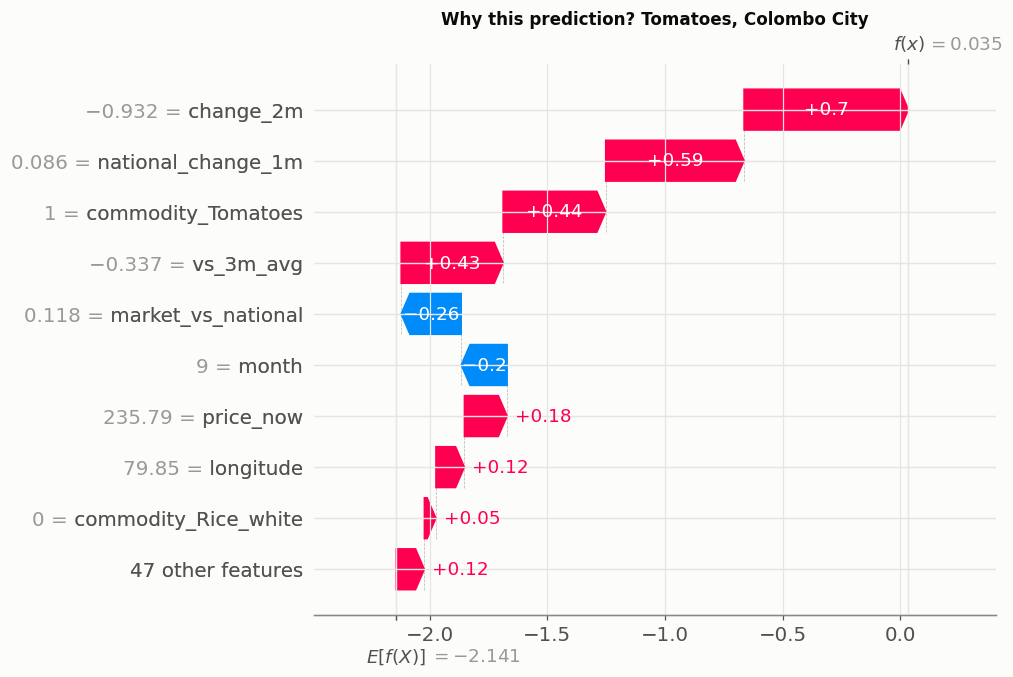

In [21]:
x_hold = hold[FEATURES].to_frame().T.astype(float)
sv_h, base_h = positive_class_shap(best, x_hold)
plt.figure()
shap.plots.waterfall(shap.Explanation(values=sv_h[0], base_values=base_h, data=x_hold.iloc[0].values, feature_names=FEATURES), max_display=10, show=False)
plt.title('Why this prediction? Tomatoes, Colombo City', fontsize=11); plt.savefig(ROOT/'outputs'/'shap_waterfall.png', dpi=130, bbox_inches='tight'); plt.show()

## 8. Retrain the selected model on all data and save it for the app
The winner is retrained on all rows (train + validation + test, still excluding the held-out row) so it has seen the most recent months.

In [22]:
final_model = clone(best)
if FAST: final_model.fit(X_train, y_train)
else:    final_model.fit(data[FEATURES], data['spike'])
joblib.dump(final_model, ROOT/'models'/'best_model.joblib')
json.dump(FEATURES, open(ROOT/'models'/'feature_columns.json', 'w'))
mk = d.drop_duplicates('market')[['market', 'latitude', 'longitude']].merge(raw[['market', 'admin1', 'admin2']].drop_duplicates('market'), on='market')
json.dump({r.market: {'province': r.admin1, 'district': r.admin2, 'latitude': float(r.latitude), 'longitude': float(r.longitude)} for r in mk.itertuples()},
          open(ROOT/'models'/'markets.json', 'w'), indent=1)
json.dump({PRETTY[c.replace('commodity_', '')]: c for c in sorted(COMM)}, open(ROOT/'models'/'commodities.json', 'w'), indent=1)   # display name -> model column
meta = {'model': best_name, 'threshold': round(thr, 4), 'spike_definition': f'price rises {int(SPIKE*100)}% or more next month',
        'val_AUC': round(float(res.loc[best_name, 'Val_AUC']), 3), 'test_AUC': round(float(res.loc[best_name, 'Test_AUC']), 3),
        'test_PR_AUC': round(float(res.loc[best_name, 'Test_PR_AUC']), 3), 'test_precision': round(float(res.loc[best_name, 'Test_Precision']), 3),
        'test_recall': round(float(res.loc[best_name, 'Test_Recall']), 3), 'spike_rate_test': round(float(y_test.mean()), 3),
        'shap_unit': 'probability' if best_name == 'Random Forest' else 'log-odds', 'trained_on': 'prices up to ' + str(data.ym.max())}
json.dump(meta, open(ROOT/'models'/'meta.json', 'w'), indent=2)
inv = {'commodity': [PRETTY[c.replace('commodity_', '')] for c in COMM if hold[c] == 1][0], 'market': hold['market'],
       'month': int(hold['month']), 'price_now': float(hold['price_now']), 'price_prev': float(hold['price_prev']), 'price_3m': float(hold['price_3m']),
       'national_avg_now': round(float(hold['nat_now']), 2), 'national_avg_prev': round(float(hold['nat_prev']), 2),
       'actual_next_price': float(hold['price']), 'actual_spike': int(hold['spike'])}
json.dump(inv, open(ROOT/'models'/'holdout_example.json', 'w'), indent=2)
data[['market', 'ym', 'price', 'spike'] + FEATURES].assign(ym=data.ym.astype(str)).to_csv(ROOT/'data'/'spike_dataset.csv', index=False)
print(meta); print(inv)

{'model': 'LightGBM', 'threshold': 0.1842, 'spike_definition': 'price rises 10% or more next month', 'val_AUC': 0.8, 'test_AUC': 0.692, 'test_PR_AUC': 0.282, 'test_precision': 0.274, 'test_recall': 0.608, 'spike_rate_test': 0.171, 'shap_unit': 'log-odds', 'trained_on': 'prices up to 2025-09'}
{'commodity': 'Tomatoes', 'market': 'Colombo City', 'month': 9, 'price_now': 235.79, 'price_prev': 213.29, 'price_3m': 541.56, 'national_avg_now': 209.63, 'national_avg_prev': 192.45, 'actual_next_price': 243.66, 'actual_spike': 0}


## 9. Inference on the held-out row

In [23]:
p_tr = float(best.predict_proba(x_hold[FEATURES])[0, 1]); p_fin = float(final_model.predict_proba(x_hold[FEATURES])[0, 1])
print('Item / market      :', inv['commodity'], '/', inv['market'])
print('Prices (3m ago, prev, now):', inv['price_3m'], inv['price_prev'], inv['price_now'], 'LKR')
print(f'Spike probability  : {p_tr:.1%} (model trained on the training period) | {p_fin:.1%} (deployed model)')
print(f'Alert threshold    : {thr:.2f} -> ' + ('SPIKE ALERT' if p_fin >= thr else 'no alert'))
print(f"What actually happened: next price {inv['actual_next_price']} LKR ({inv['actual_next_price']/inv['price_now']-1:+.1%}) -> spike = {bool(inv['actual_spike'])}")

Item / market      : Tomatoes / Colombo City
Prices (3m ago, prev, now): 541.56 213.29 235.79 LKR
Spike probability  : 50.9% (model trained on the training period) | 44.6% (deployed model)
Alert threshold    : 0.18 -> SPIKE ALERT
What actually happened: next price 243.66 LKR (+3.3%) -> spike = False


## 10. Conclusions
* Compare each model with the **baseline**: a model is only useful if it beats "this item's usual spike rate".
* The differences between the four models are usually small; the bootstrap table shows whether they are real.
* SHAP shows **what the model relies on**: which item, how prices moved recently, the national trend, and the season. Check that these agree with common sense before trusting the model.
* **Limits:** only past prices are used (no weather, fuel, exchange rate or import data); coverage before mid-2023 is thin; the test covers one 9-month period; and spikes are partly random, so some alerts will be false alarms.